# 04 · Error analysis: where and why does the model fail?

A single accuracy number hides a lot. Here we look at the **correlation** model from notebook 03 and ask:
1. Which group is harder to recognise?
2. Who is misclassified, and is it because of their age or their head motion?
3. Does the model's output behave like a "brain maturity" score?
4. Which connections does the model rely on, and are they stable across training sets?

*Requires the outputs of notebooks 01 and 03 in `data/`.*

In [1]:
# --- Setup -------------------------------------------------------------------
# Running on Google Colab? First run, in a new cell:
#   !git clone https://github.com/Leena2403/Brain_Network_Development_fMRI.git
#   %cd Brain_Network_Development_fMRI/notebooks
#   !pip install -q -r ../requirements.txt
import sys
sys.path.append("..")   # so we can import our own code from ../src

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from nilearn import plotting

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"child": "#E69F00", "adult": "#0072B2"}   # colour-blind-safe orange / blue
DATA_DIR = "../data"                # intermediate files (not committed to git)
FIG_DIR = "../results/figures"      # figures used in the README

def save(name):
    """Save the current figure for the README."""
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")

In [2]:
from src.feature_extraction import load_atlas

# Outputs of notebook 01
pheno = pd.read_csv(f"{DATA_DIR}/participants_clean.csv")
saved = np.load(f"{DATA_DIR}/time_series_msdl.npz", allow_pickle=True)
time_series = list(saved["time_series"])
assert list(saved["ids"]) == list(pheno["participant_id"]), "Rerun notebook 01"

atlas_maps, labels, networks, coords = load_atlas()
is_child = (pheno["Child_Adult"] == "child").values
y = (~is_child).astype(int)   # 0 = child, 1 = adult

print(f"{len(time_series)} participants ({is_child.sum()} children, {(~is_child).sum()} adults), "
      f"{time_series[0].shape[0]} time points x {time_series[0].shape[1]} regions each")

cv = np.load(f"{DATA_DIR}/cv_correlation.npz")
pheno["prob_adult"] = cv["prob_adult"]          # out-of-fold P(adult), averaged over 10 repeats
pheno["predicted"] = np.where(pheno.prob_adult > 0.5, "adult", "child")
pheno["correct"] = pheno.predicted == pheno.Child_Adult

120 participants (88 children, 32 adults), 168 time points x 39 regions each


## 1. Confusion matrix
Rows = true group, columns = prediction. Each row sums to 1, so the diagonal is the share recognised correctly in each group.

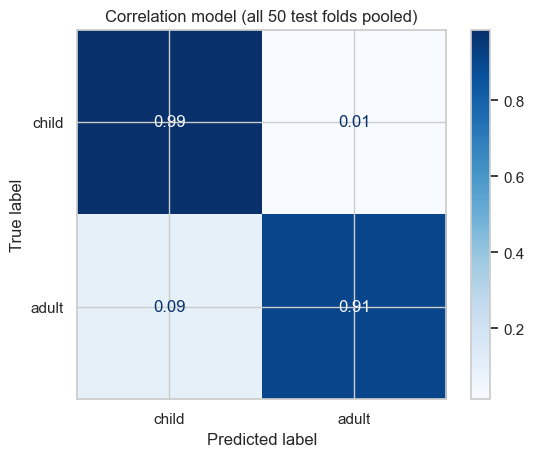

In [3]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = cv["confusion"]
ConfusionMatrixDisplay(cm / cm.sum(axis=1, keepdims=True), display_labels=["child", "adult"]) \
    .plot(cmap="Blues", values_format=".2f")
plt.title("Correlation model (all 50 test folds pooled)")
plt.show()

**Insight:** children are recognised almost perfectly (**98.6%**), adults less often (**90.6%**). Errors are **mostly adults called children**, not the other way round. The model has ~3× fewer adults to learn from, and `class_weight="balanced"` only partly makes up for that.

## 2. Who is misclassified?
Using each person's prediction averaged over the 10 repeats.

In [4]:
wrong = pheno[~pheno.correct]
print(f"{len(wrong)} of {len(pheno)} people misclassified on average\n")
wrong[["participant_id", "Child_Adult", "Age", "Gender", "mean_fd", "prob_adult"]] \
    .sort_values("Age").round(3)

4 of 120 people misclassified on average



,participant_id,Child_Adult,Age,Gender,mean_fd,prob_adult
61,sub-pixar109,child,10.38,F,0.228,0.860
20,sub-pixar150,adult,19.00,F,0.232,0.484
26,sub-pixar144,adult,20.00,F,0.319,0.057
1,sub-pixar123,adult,27.06,F,0.159,0.481


In [5]:
# Do misclassified people move more than correctly classified people of the same group?
for group in ["child", "adult"]:
    g = pheno[pheno.Child_Adult == group]
    wrong_g, right_g = g[~g.correct], g[g.correct]
    if len(wrong_g) == 0:
        print(f"{group}: no errors"); continue
    # A test needs at least 2 people in each group
    p = f"p = {stats.mannwhitneyu(wrong_g.mean_fd, right_g.mean_fd).pvalue:.2f}" if len(wrong_g) > 1 else "too few to test"
    print(f"{group:5s} ({len(wrong_g)} wrong): median FD wrong = {wrong_g.mean_fd.median():.3f} vs "
          f"correct = {right_g.mean_fd.median():.3f} ({p}); "
          f"median age wrong = {wrong_g.Age.median():.1f} vs correct = {right_g.Age.median():.1f}")

child (1 wrong): median FD wrong = 0.228 vs correct = 0.220 (too few to test); median age wrong = 10.4 vs correct = 5.8
adult (3 wrong): median FD wrong = 0.232 vs correct = 0.152 (p = 0.16); median age wrong = 20.0 vs correct = 23.0


**Insights**
- Only **4 of 120** people are misclassified on average: **1 child** and **3 adults**.
- The misclassified child is **10.4 years old**, one of the oldest children, and the model is fairly confident they're an adult (P = 0.86).
- Two of the three misclassified adults are among the **youngest adults (19 and 20 y)**; two sit right on the boundary (P ≈ 0.48).
- Their motion is not unusual. With only 1–3 people per group this is weak evidence, but errors look like **age-boundary cases, not motion artefacts**.

## 3. Is P(adult) a "brain maturity" score?

The model was only told *child* or *adult*; it never saw anyone's age. If its output still rises with age **within the children**, the connectivity pattern changes gradually through childhood rather than flipping at one point. We check the same for head motion, and use a partial correlation to separate the two.

Children only (n = 88):
  P(adult) vs age:          rho = +0.42, p = 5.33e-05
  P(adult) vs motion:       rho = -0.38, p = 0.000294
  P(adult) vs age | motion: rho = +0.40, p = 9.72e-05


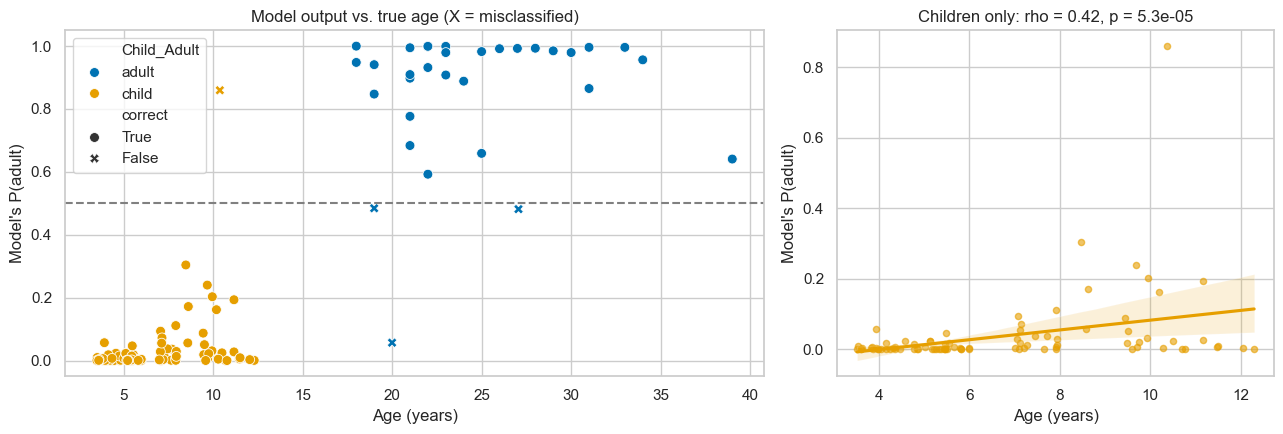

In [6]:
def partial_spearman(df, x, y_, covar):
    """Spearman correlation between x and y after removing a covariate from both (on ranks)."""
    r = df[[x, y_, covar]].rank()
    res = lambda a: r[a] - np.polyval(np.polyfit(r[covar], r[a], 1), r[covar])
    return stats.pearsonr(res(x), res(y_))

kids = pheno[is_child]
r_age = stats.spearmanr(kids.Age, kids.prob_adult)
r_fd = stats.spearmanr(kids.mean_fd, kids.prob_adult)
pr_age = partial_spearman(kids, "Age", "prob_adult", "mean_fd")
print(f"Children only (n = {len(kids)}):")
print(f"  P(adult) vs age:          rho = {r_age.statistic:+.2f}, p = {r_age.pvalue:.3g}")
print(f"  P(adult) vs motion:       rho = {r_fd.statistic:+.2f}, p = {r_fd.pvalue:.3g}")
print(f"  P(adult) vs age | motion: rho = {pr_age.statistic:+.2f}, p = {pr_age.pvalue:.3g}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
sns.scatterplot(data=pheno, x="Age", y="prob_adult", hue="Child_Adult", style="correct",
                style_order=[True, False], markers={True: "o", False: "X"}, palette=PALETTE,
                s=50, ax=axes[0])
axes[0].axhline(0.5, ls="--", c="gray")
axes[0].set(xlabel="Age (years)", ylabel="Model's P(adult)",
            title="Model output vs. true age (X = misclassified)")
sns.regplot(data=kids, x="Age", y="prob_adult", color=PALETTE["child"], ax=axes[1],
            scatter_kws={"s": 20, "alpha": 0.6})
axes[1].set(xlabel="Age (years)", ylabel="Model's P(adult)",
            title=f"Children only: rho = {r_age.statistic:.2f}, p = {r_age.pvalue:.2g}")
plt.tight_layout(); save("04_prob_vs_age"); plt.show()

**Insights**
- Even though the model never saw anyone's age, **its P(adult) rises with age among children** (ρ = 0.42, p = 5 × 10⁻⁵), and this **holds after controlling for motion** (partial ρ = 0.40). Connectivity seems to mature **gradually** through childhood rather than switching at one point.
- Most children still sit near 0 even at 12 years, so a large part of the change likely happens in **adolescence**, the age range this dataset doesn't include.
- Children who move more look more child-like (ρ = −0.38). This is partly because younger children move more, which is why we check the partial correlation.

## 4. Which connections does the model rely on?

Weights from a single model can be unstable when there are 741 features and only ~120 people. So we use the 50 models trained during cross-validation and count how often each connection is in the **top 20 by |weight|**. Connections that keep appearing are the ones the result really depends on.

*Positive weight = stronger in adults; negative = stronger in children.*

In [7]:
from src.feature_extraction import edge_table, vector_to_matrix
from src.evaluation import top_k_frequency

weights = cv["weights"]                     # (50 folds, 741 connections)
edges = edge_table(labels, networks, coords)
edges["mean_weight"] = weights.mean(axis=0)
edges["sign_agreement"] = (np.sign(weights) == np.sign(weights.mean(0))).mean(axis=0)
edges["top20_freq"] = top_k_frequency(weights, k=20)

stable = edges.sort_values("top20_freq", ascending=False)
print(f"Connections in the top 20 in at least 80% of folds: {(edges.top20_freq >= 0.8).sum()}")
stable.head(15)[["region_A", "network_A", "region_B", "network_B", "distance_mm",
                 "mean_weight", "sign_agreement", "top20_freq"]].round(3)

Connections in the top 20 in at least 80% of folds: 3


,region_A,network_A,region_B,network_B,distance_mm,mean_weight,sign_agreement,top20_freq
664,R Ins,Cing-Ins,L Ins,Cing-Ins,84.343,0.116,1.0,0.90
401,Broca,Language,V ACC,Salience,51.286,-0.117,1.0,0.88
510,Cereb,Cereb,L Par,L V Att,80.743,0.113,1.0,0.86
402,Broca,Language,R A Ins,Salience,81.953,-0.107,1.0,0.78
503,Cereb,Cereb,Occ post,Occ post,41.356,0.110,1.0,0.76
350,R STS,Temporal,L STS,Temporal,104.824,0.103,1.0,0.72
362,L TPJ,Language,R Par,R V Att,108.544,-0.103,1.0,0.68
132,L Front pol,L V Att,R Post Temp,R V Att,132.753,0.101,1.0,0.66
307,L STS,Temporal,Occ post,Occ post,90.798,0.102,1.0,0.62
654,R Ins,Cing-Ins,R A Ins,Salience,41.291,0.098,1.0,0.50


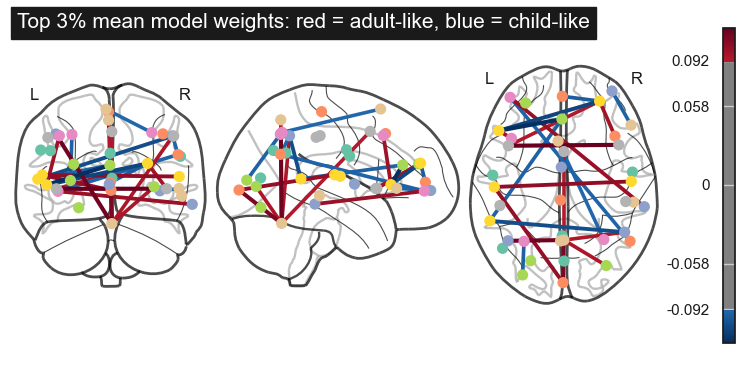

Share within the same network: top 30 = 10% | all connections = 5%
Adult-like (positive) among top 30: 16


In [8]:
w_mat = vector_to_matrix(edges.mean_weight.values, len(labels))
plotting.plot_connectome(w_mat, coords, edge_threshold="97%", edge_cmap="RdBu_r", colorbar=True,
                         title="Top 3% mean model weights: red = adult-like, blue = child-like")
save("04_model_weights"); plt.show()

# Are the most important connections mostly within or between networks?
top = edges.nlargest(30, "top20_freq")
print("Share within the same network: top 30 = "
      f"{top.same_network.mean():.0%} | all connections = {edges.same_network.mean():.0%}")
print("Adult-like (positive) among top 30:", (top.mean_weight > 0).sum())

**Insights**
- The important connections are **stable**: the top 15 have the **same sign in 100% of folds**, and the strongest (right ↔ left insula) is in the top 20 in 90% of folds.
- **Adult-like (stronger in adults):** left ↔ right insula, left ↔ right STS, and **cerebellum** ↔ parietal/occipital cortex.
- **Child-like (stronger in children):** **Broca's area ↔ salience regions** (ventral ACC, right anterior insula) and right anterior insula ↔ frontal DMN. These cross-network couplings weaken with age, in line with notebook 02.
- Only 3 connections are in the top 20 in ≥ 80% of folds, so the model relies on a **distributed pattern** across many connections, not a few "key" ones.
- Within-network links are over-represented among the most important connections (10% vs. 5% overall), but most are still *between* networks.

*Caution:* the 741 features are correlated with each other, so weights show which patterns the model uses. They are not proof that a single connection causes anything.

## Summary

| Question | Answer |
|---|---|
| Which group is harder? | Adults (90.6% vs. 98.6% correct): fewer training examples |
| Who is misclassified? | 4 / 120: an older child (10.4 y) and mostly young adults, i.e. boundary cases |
| Do errors come from motion? | No clear sign (very few errors to test) |
| Maturity score? | Yes: P(adult) rises with age within children (ρ = 0.42), independent of motion |
| What does the model use? | A stable, distributed pattern: inter-hemispheric insula/STS and cerebellar links (adult) vs. language–salience and salience–DMN links (child) |

### Ideas for next steps
- Predict **age as a number** (regression) instead of child vs. adult.
- Add an **adolescent** dataset to see where the big jump happens.
- Check **robustness** with a different atlas (e.g. Schaefer-100) and stricter motion scrubbing.
- Test on an **independent dataset** (e.g. ABIDE controls, HBN).